# 03 · Líneas base tabulares — M0 (diámetro), M1 (metadatos) y M2 (atributos semánticos)

**M0** es la línea base de la Tabla 21 del TFM: se trata de hacer una regresión logística con el diámetro del nódulo. Es la referencia mínima que debe superar el modelo de imagen (H1).

Este notebook no contiene lógica de entrenamiento. Llama a `tfm_lidc.lineas_base.ejecutar`, que es el mismo código que se lanza desde la terminal, y se dedica a mostrar y analizar los resultados. La parte 2 trata M1 y la parte 3, M2; cada modelo tiene su propio archivo de configuración.

| Elemento | Decisión (Tabla 19) |
|---|---|
| Unidad | Nódulo con etiqueta R1 (≥ 3 lectores; mediana < 3 baja, > 3 alta, = 3 excluido) |
| Partición | 5 pliegues externos agrupados por paciente y estratificados; validación interna ≈ 16 % por pliegue |
| Umbral | Youden en la validación interna de cada pliegue |
| Métricas | Sobre las predicciones fuera de pliegue; IC 95 % por bootstrap de pacientes |

**Requisitos:** kernel «Python (TFM)» con el paquete instalado (`pip install -e ".[dev]"`) y la partición versionada en `particiones/`.

## 0. Configuración

In [1]:
%load_ext autoreload
%autoreload 2

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve

from tfm_lidc import config
from tfm_lidc.data import nodulos as dn
from tfm_lidc.lineas_base import ejecutar

# Raíz del repositorio: la primera carpeta hacia arriba que contiene pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CFG_M0 = REPO / "configs/modelos/m0_diametro.yaml"
N_CONTROL = 200          # repeticiones del control negativo (0 para omitirlo)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("Repositorio:", REPO)

Repositorio: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai-m2


## 1. Ejecución de M0

In [2]:
r = ejecutar(str(CFG_M0), n_control=N_CONTROL)
cfg = config.cargar(CFG_M0)
d = r["datos"]
print(f"{r['modelo']} · {d['regla']} · {d['nodulos']} nódulos de {d['pacientes']} pacientes · "
      f"{d['alta_sospecha']} de alta sospecha ({d['alta_sospecha']/d['nodulos']:.1%})")
print(f"Partición: huella {d['huella_particion']} · commit {r['commit']} · {r['entorno']['maquina']}")
print(f"Resultados en: {r['carpeta_resultados']}")

M0 · R1 · 869 nódulos de 530 pacientes · 421 de alta sospecha (48.4%)
Partición: huella 0e6393241e7c69e0 · commit b54ad8c-modificado · macOS-26.7.3-arm64-arm-64bit
Resultados en: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai-m2/resultados/m0_diametro__R1__s42__b54ad8c-modificado


## 2. Métricas de prueba con IC 95 %

In [3]:
nombres = dict(auc="AUC", auprc="AUPRC", brier="Brier (menor es mejor)", exactitud="Exactitud",
               sensibilidad="Sensibilidad", especificidad="Especificidad")
tabla = pd.DataFrame([dict(métrica=nombres[k], valor=v["valor"], ic95_inf=v["ic95"][0], ic95_sup=v["ic95"][1])
                      for k, v in r["metricas"].items()]).set_index("métrica")
tabla.round(3)

,valor,ic95_inf,ic95_sup
métrica,,,
AUC,0.936,0.917,0.952
AUPRC,0.926,0.899,0.950
Brier (menor es mejor),0.101,0.087,0.117
Exactitud,0.853,0.826,0.877
Sensibilidad,0.822,0.776,0.862
Especificidad,0.882,0.850,0.911


## 3. Resultados por pliegue

In [4]:
pred = pd.read_csv(Path(r["carpeta_resultados"]) / "predicciones_oof.csv")
por_pliegue = pred.groupby("pliegue").agg(nódulos=("nodule_id", "size"), pacientes=("patient_id", "nunique"),
                                          alta_sospecha=("etiqueta", "mean"))
por_pliegue["AUC prueba"] = r["auc_prueba_por_pliegue"]
por_pliegue["umbral"] = r["umbrales_por_pliegue"]
por_pliegue["coef. diámetro (est.)"] = [c["diametro_mm"] for c in r["coeficientes_por_pliegue"]]
por_pliegue["intercepto"] = [c["intercepto"] for c in r["coeficientes_por_pliegue"]]
display(por_pliegue.round({"alta_sospecha": 3, "AUC prueba": 3, "umbral": 3, "coef. diámetro (est.)": 3, "intercepto": 3}))
a = np.array(r["auc_prueba_por_pliegue"])
print(f"AUC entre pliegues: media {a.mean():.3f} · DT {a.std(ddof=1):.3f} · rango {a.min():.3f}–{a.max():.3f}")

,nódulos,pacientes,alta_sospecha,AUC prueba,umbral,coef. diámetro (est.),intercepto
pliegue,,,,,,,
0,159,108,0.553,0.948,0.557,3.924,0.821
1,196,106,0.485,0.946,0.524,3.596,0.786
2,173,111,0.491,0.934,0.516,3.893,0.683
3,172,100,0.483,0.905,0.268,4.590,1.106
4,169,105,0.414,0.952,0.437,3.775,0.906


AUC entre pliegues: media 0.937 · DT 0.019 · rango 0.905–0.952


## 4. Curvas ROC, calibración y relación con el diámetro

* **ROC:** curva conjunta de las 869 predicciones fuera de pliegue y la de cada pliegue.
* **Calibración:** proporción observada de alta sospecha frente a la probabilidad predicha (10 intervalos).
* **Probabilidad frente a diámetro:** la curva logística de M0 (una por pliegue) y, en los extremos, cada nódulo según su clase real; las líneas verticales marcan el diámetro equivalente al umbral de cada pliegue. Los nódulos de una clase que caen al otro lado de esas líneas son los errores de M0.

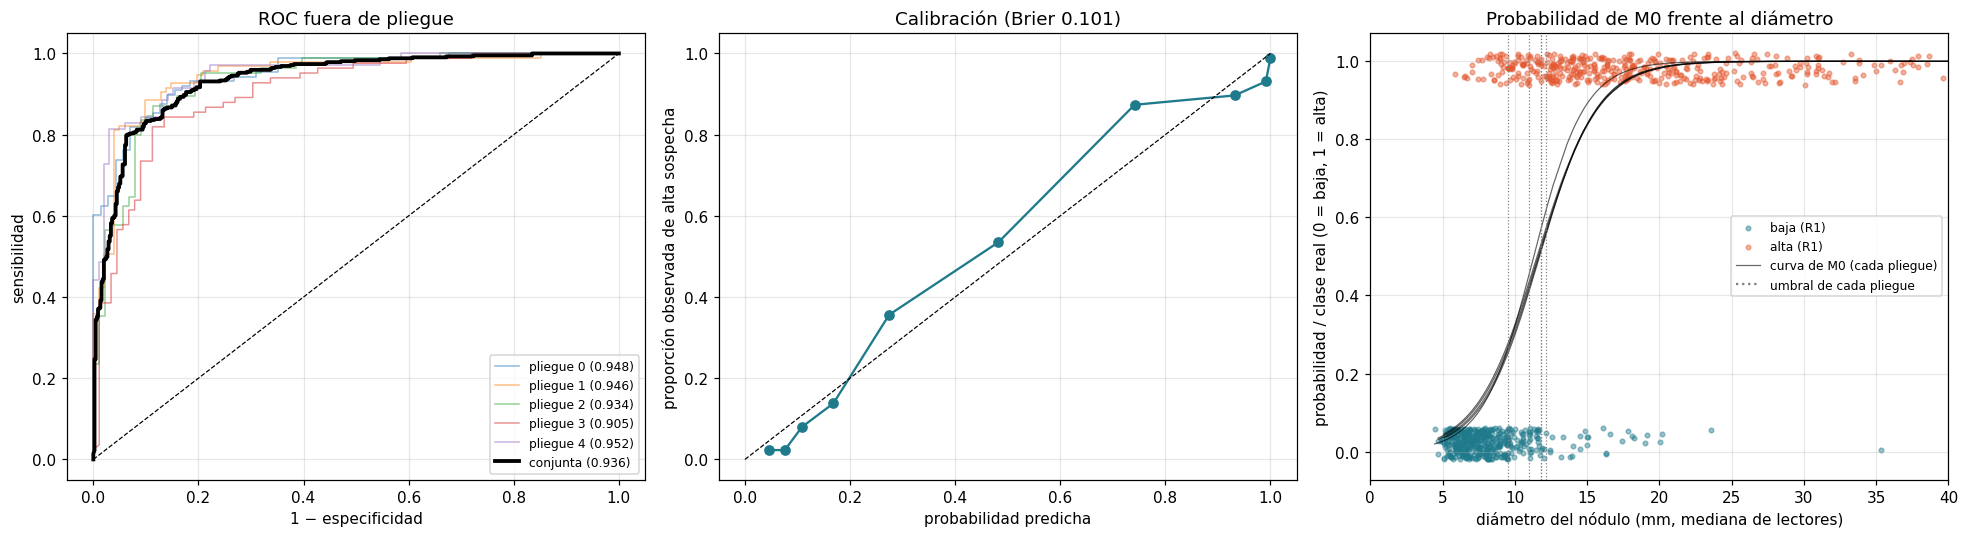

Diámetro equivalente al umbral de cada pliegue (mm): [12.2 11.8 11.8  9.6 11. ]


In [5]:
nod = dn.construir_o_cargar(cfg, REPO / cfg["salidas"]["dir_resultados"] / "datos")
pred = pred.merge(nod[["nodule_id", "diametro_mm"]], on="nodule_id", validate="one_to_one")
y, p = pred.etiqueta.values, pred.probabilidad.values

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for k, g in pred.groupby("pliegue"):
    f, t, _ = roc_curve(g.etiqueta, g.probabilidad)
    ax[0].plot(f, t, lw=1, alpha=.5, label=f"pliegue {k} ({r['auc_prueba_por_pliegue'][k]:.3f})")
f, t, _ = roc_curve(y, p)
ax[0].plot(f, t, lw=2.5, c="k", label=f"conjunta ({roc_auc_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set(title="ROC fuera de pliegue", xlabel="1 − especificidad", ylabel="sensibilidad"); ax[0].legend(fontsize=8)

obs, esp = calibration_curve(y, p, n_bins=10, strategy="quantile")
ax[1].plot(esp, obs, "o-", c="#1f7a8c"); ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
ax[1].set(title=f"Calibración (Brier {r['metricas']['brier']['valor']:.3f})", xlabel="probabilidad predicha",
          ylabel="proporción observada de alta sospecha")

rng = np.random.default_rng(0)
for etq, col, lab in ((0, "#1f7a8c", "baja (R1)"), (1, "#e4572e", "alta (R1)")):
    g = pred[pred.etiqueta == etq]
    ax[2].scatter(g.diametro_mm, etq + rng.uniform(-.04, .04, len(g)) * (1 if etq == 0 else -1) + (0.02 if etq == 0 else -0.02),
                  c=col, s=9, alpha=.45, label=lab)
for k, g in pred.groupby("pliegue"):
    g = g.sort_values("diametro_mm")
    ax[2].plot(g.diametro_mm, g.probabilidad, c="k", lw=.8, alpha=.6, label="curva de M0 (cada pliegue)" if k == 0 else None)
for k, u in enumerate(r["umbrales_por_pliegue"]):
    g = pred[pred.pliegue == k].sort_values("diametro_mm")
    corte = np.interp(u, g.probabilidad.values, g.diametro_mm.values)   # la curva es monótona creciente
    ax[2].axvline(corte, c="grey", lw=.8, ls=":")
ax[2].set(title="Probabilidad de M0 frente al diámetro", xlabel="diámetro del nódulo (mm, mediana de lectores)",
          ylabel="probabilidad / clase real (0 = baja, 1 = alta)", xlim=(0, 40))
ax[2].plot([], [], c="grey", ls=":", label="umbral de cada pliegue"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

cortes = []
for k, u in enumerate(r["umbrales_por_pliegue"]):
    g = pred[pred.pliegue == k].sort_values("diametro_mm")
    cortes.append(np.interp(u, g.probabilidad.values, g.diametro_mm.values))
print("Diámetro equivalente al umbral de cada pliegue (mm):", np.round(cortes, 1))

## 5. Matriz de confusión y análisis de errores

,predicho: baja,predicho: alta
real: baja,395,53
real: alta,75,346


,nódulos,25%,mediana,75%
resultado,,,,
FN,75.0,8.8,9.7,10.6
FP,53.0,11.0,12.5,16.1
VN,395.0,6.3,7.2,8.4
VP,346.0,14.6,18.5,24.6


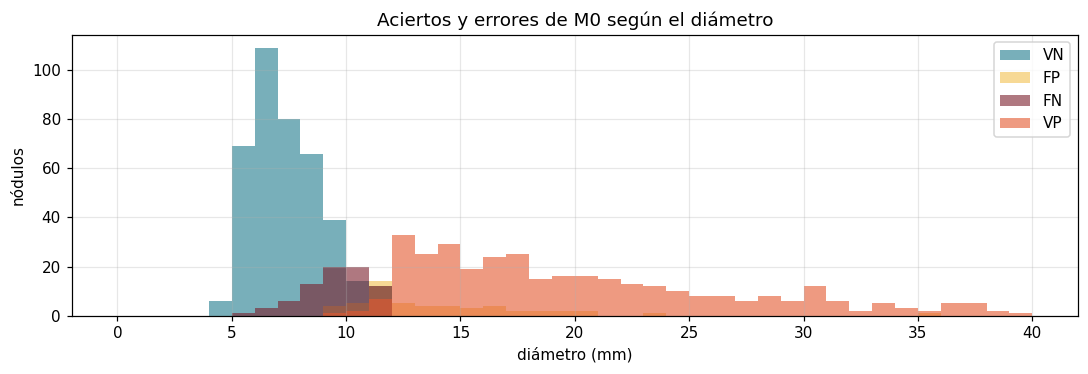

Los falsos negativos son nódulos de alta sospecha pequeños y los falsos positivos, de baja sospecha grandes: es el margen que el modelo de imagen tendría que recuperar para superar a M0 (H1).


In [6]:
cm = confusion_matrix(pred.etiqueta, pred.prediccion)
display(pd.DataFrame(cm, index=["real: baja", "real: alta"], columns=["predicho: baja", "predicho: alta"]))

pred["resultado"] = np.select(
    [(pred.etiqueta == 1) & (pred.prediccion == 1), (pred.etiqueta == 0) & (pred.prediccion == 0),
     (pred.etiqueta == 0) & (pred.prediccion == 1)], ["VP", "VN", "FP"], "FN")
display(pred.groupby("resultado").diametro_mm.describe()[["count", "25%", "50%", "75%"]].round(1)
        .rename(columns={"count": "nódulos", "50%": "mediana"}))

fig, ax = plt.subplots(figsize=(10, 3.5))
for res, c in (("VN", "#1f7a8c"), ("FP", "#f2c14e"), ("FN", "#7a1f2b"), ("VP", "#e4572e")):
    ax.hist(pred.diametro_mm[pred.resultado == res], bins=np.arange(0, 41, 1), alpha=.6, label=res, color=c)
ax.set(xlabel="diámetro (mm)", ylabel="nódulos", title="Aciertos y errores de M0 según el diámetro"); ax.legend()
plt.tight_layout(); plt.show()
print("Los falsos negativos son nódulos de alta sospecha pequeños y los falsos positivos, de baja sospecha grandes: "
      "es el margen que el modelo de imagen tendría que recuperar para superar a M0 (H1).")

## 6. Control negativo

M0 se reentrena con las etiquetas de entrenamiento permutadas y se evalúa contra las etiquetas reales de prueba (Tabla 19). Sin fuga, el AUC medio debe rondar 0,5.

Con una sola variable el modelo solo puede aprender el signo de la relación, así que el AUC salta entre valores altos y bajos. En M0 la prueba es poco informativa; será relevante en M3–M7.

In [7]:
c = r["control_negativo"]
if c:
    print(f"{c['n_permutaciones']} permutaciones · AUC media {c['auc_media']:.3f} · "
          f"percentiles 2,5–97,5 %: [{c['auc_p2_5']:.3f}, {c['auc_p97_5']:.3f}] · "
          f"{'superado' if c['superado'] else 'NO superado'}")
else:
    print("Control negativo omitido (N_CONTROL = 0)")

200 permutaciones · AUC media 0.473 · percentiles 2,5–97,5 %: [0.191, 0.719] · superado


## 7. Comprobación de los datos frente a Hancock y Magnan (2016) — opcional

El artículo no tiene un modelo solo con el diámetro, pero su experimento uno permite validar la lectura de LIDC-IDRI: con su protocolo (anotación como unidad, sin la publicación inicial, 75/25 aleatorio) deben salir su cohorte (2.817 anotaciones de 530 exploraciones) y su Tabla 4. No forma parte del protocolo del TFM. Tarda 1–2 minutos con 1.000 repeticiones.

In [8]:
EJECUTAR_REPLICA = False
if EJECUTAR_REPLICA:
    import subprocess, sys
    print(subprocess.run([sys.executable, str(REPO / "scripts/replica_hancock_magnan.py"), "--repeticiones", "1000"],
                         capture_output=True, text=True).stdout)
else:
    print("Réplica omitida: cambia EJECUTAR_REPLICA a True para ejecutarla.")

Réplica omitida: cambia EJECUTAR_REPLICA a True para ejecutarla.


## 8. Registro de la ejecución

Todo lo necesario para auditar el resultado queda en `registro.json`: configuración y su huella, commit, huella de la partición, umbrales, coeficientes, métricas y entorno.

In [9]:
print(json.dumps({k: r[k] for k in ("experimento", "commit", "fecha", "huella_configuracion", "entorno", "duracion_s")},
                 indent=1, ensure_ascii=False))

{
 "experimento": "m0_diametro__R1__s42__b54ad8c-modificado",
 "commit": "b54ad8c-modificado",
 "fecha": "2026-11-19 14:48:45",
 "huella_configuracion": "dd473c6911d7",
 "entorno": {
  "python": "3.11.18",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "sklearn": "1.7.2",
  "maquina": "macOS-26.7.3-arm64-arm-64bit"
 },
 "duracion_s": 7.0
}


---
# Parte 2 · M1 — metadatos de adquisición

**M1** es el detector de atajos y de confusión de la Tabla 21: una regresión logística que intenta predecir la etiqueta **solo con cómo se adquirió la TC**, sin mirar el nódulo (DeGrave et al., 2021; Geirhos et al., 2020). Se usa la variante **solo metadatos**, sin diámetro.

| Variable | Fuente | Tipo |
|---|---|---|
| Grosor de corte (mm) | pylidc | Numérica |
| Espaciado en el plano (mm/píxel) | pylidc | Numérica |
| Espaciado entre cortes (mm) | pylidc | Numérica |
| Uso de contraste | pylidc | Binaria |
| Fabricante (GE, Siemens, Philips, Toshiba) | `metadata.csv` de TCIA | Categórica (one-hot) |

**Cómo se interpreta:**

| Resultado | Significa | Consecuencia para M3–M7 |
|---|---|---|
| AUC ≈ 0,5 y p-valor de permutación alto | La adquisición no informa de la etiqueta | Atajo descartado; se documenta como amenaza controlada |
| AUC > 0,5 con p-valor bajo pero AUC pequeño (< 0,6) | Asociación débil pero real | Evaluar los modelos de imagen estratificando por las variables implicadas |
| AUC claramente alto | La adquisición predice la etiqueta | Riesgo serio de atajo: ajustar, estratificar o filtrar antes de entrenar con imagen |

**Requisito:** `datos.metadata_csv` en `configs/local.yaml` con la ruta a `TCIA_LIDC-IDRI_20200921/metadata/metadata.csv`.

## 9. Ejecución de M1 (con prueba de permutación)

In [10]:
CFG_M1 = REPO / "configs/modelos/m1_metadatos.yaml"
N_CONTROL_M1 = 1000          # permutaciones: dan el control negativo y el p-valor del AUC observado
r1 = ejecutar(str(CFG_M1), n_control=N_CONTROL_M1)
cfg1 = config.cargar(CFG_M1)
c1 = r1["control_negativo"]
print(f"{r1['modelo']} · {r1['datos']['nodulos']} nódulos · partición {r1['datos']['huella_particion']}")
print(f"AUC {r1['metricas']['auc']['valor']:.3f} [{r1['metricas']['auc']['ic95'][0]:.3f}, {r1['metricas']['auc']['ic95'][1]:.3f}] · "
      f"p-valor por permutación {c1['p_valor']:.4f} ({c1['n_permutaciones']} permutaciones)")

M1 · 869 nódulos · partición 0e6393241e7c69e0
AUC 0.541 [0.496, 0.588] · p-valor por permutación 0.0470 (1000 permutaciones)


## 10. M1 frente a M0

In [11]:
comp = pd.DataFrame({
    f"{mod} · {k}": {nombres[m]: v[m][k2] if k2 == "valor" else v[m]["ic95"][k2] for m in v}
    for mod, v in (("M0", r["metricas"]), ("M1", r1["metricas"]))
    for k, k2 in (("valor", "valor"), ("IC inf", 0), ("IC sup", 1))
}).round(3)
display(comp)
print("AUC de prueba por pliegue · M0:", r["auc_prueba_por_pliegue"])
print("AUC de prueba por pliegue · M1:", r1["auc_prueba_por_pliegue"])

,M0 · valor,M0 · IC inf,M0 · IC sup,M1 · valor,M1 · IC inf,M1 · IC sup
AUC,0.936,0.917,0.952,0.541,0.496,0.588
AUPRC,0.926,0.899,0.950,0.514,0.463,0.578
Brier (menor es mejor),0.101,0.087,0.117,0.252,0.244,0.258
Exactitud,0.853,0.826,0.877,0.533,0.491,0.576
Sensibilidad,0.822,0.776,0.862,0.601,0.541,0.662
Especificidad,0.882,0.850,0.911,0.469,0.402,0.539


AUC de prueba por pliegue · M0: [0.9483, 0.9455, 0.9337, 0.9046, 0.9519]
AUC de prueba por pliegue · M1: [0.5649, 0.4879, 0.6053, 0.5395, 0.5439]


## 11. Qué metadatos pesan en M1

Coeficientes de la regresión logística en cada pliegue. Las variables numéricas están estandarizadas: el coeficiente es el cambio en log-odds por cada desviación típica. El **odds ratio** (OR = e^coef) de un fabricante se interpreta frente a la media de los cuatro, porque todos están codificados sin categoría de referencia. Un efecto es más creíble si **mantiene el signo en los 5 pliegues**.

,media,DT,OR (e^media),pliegues con el mismo signo
fabricante_Philips,0.487,0.123,1.627,5
fabricante_Siemens,-0.284,0.185,0.753,5
espaciado_z_mm,0.228,0.181,1.256,5
contraste,0.143,0.063,1.153,5
fabricante_Toshiba,-0.135,0.290,0.874,4
fabricante_GE,-0.062,0.127,0.940,3
px_mm,0.038,0.048,1.039,4
grosor_mm,-0.014,0.138,0.986,3


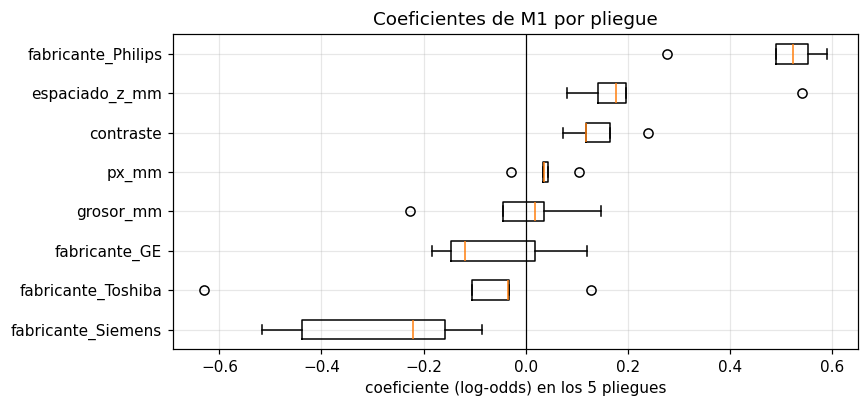

In [12]:
coef1 = pd.DataFrame(r1["coeficientes_por_pliegue"]).drop(columns="intercepto")
res_coef = pd.DataFrame({"media": coef1.mean(), "DT": coef1.std(ddof=1), "OR (e^media)": np.exp(coef1.mean()),
                         "pliegues con el mismo signo": coef1.apply(lambda c: max((c > 0).sum(), (c < 0).sum()))})
display(res_coef.sort_values("media", key=abs, ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
orden = coef1.mean().sort_values().index
ax.boxplot([coef1[c] for c in orden], orientation="horizontal", tick_labels=list(orden))
ax.axvline(0, c="k", lw=.8); ax.set(xlabel="coeficiente (log-odds) en los 5 pliegues", title="Coeficientes de M1 por pliegue")
plt.tight_layout(); plt.show()

## 12. Asociación de cada metadato con la etiqueta (R1)

Análisis univariante sobre los 869 nódulos: proporción de alta sospecha por categoría, con χ² y V de Cramér para las categóricas, y Mann-Whitney para las numéricas. Es descriptivo (usa todos los nódulos) y sirve para entender qué hay detrás del AUC de M1, no para evaluarlo.

In [13]:
from scipy import stats

nod1 = dn.construir_o_cargar(cfg1, REPO / cfg1["salidas"]["dir_resultados"] / "datos")
d1 = nod1.dropna(subset=["etiqueta_r1"]).copy()
d1["etiqueta"] = d1.etiqueta_r1.astype(int)
d1["grosor_cat"] = pd.cut(d1.grosor_mm, [0, 1.5, 2.5, 10], labels=["≤ 1,5 mm", "1,5–2,5 mm", "> 2,5 mm"])

def tabla_cat(col):
    t = pd.crosstab(d1[col], d1.etiqueta)
    chi2, p, *_ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    out = pd.DataFrame({"nódulos": t.sum(axis=1), "% alta sospecha": (t[1] / t.sum(axis=1) * 100).round(1)})
    print(f"{col}: χ² = {chi2:.1f}, p = {p:.3g}, V de Cramér = {v:.3f}")
    display(out)

for col in ["fabricante", "grosor_cat", "contraste"]:
    tabla_cat(col)

filas = []
for col in ["px_mm", "espaciado_z_mm", "grosor_mm"]:
    a, b = d1.loc[d1.etiqueta == 0, col], d1.loc[d1.etiqueta == 1, col]
    filas.append(dict(variable=col, mediana_baja=a.median(), mediana_alta=b.median(),
                      p_MannWhitney=stats.mannwhitneyu(a, b).pvalue))
display(pd.DataFrame(filas).round(4))

fabricante: χ² = 7.3, p = 0.0629, V de Cramér = 0.092


,nódulos,% alta sospecha
fabricante,,
GE,531,49.3
Philips,75,53.3
Siemens,201,41.3
Toshiba,62,58.1


grosor_cat: χ² = 9.2, p = 0.0102, V de Cramér = 0.103


,nódulos,% alta sospecha
grosor_cat,,
"≤ 1,5 mm",382,42.7
"1,5–2,5 mm",360,53.3
"> 2,5 mm",127,52.0


contraste: χ² = 11.4, p = 0.000735, V de Cramér = 0.115


,nódulos,% alta sospecha
contraste,,
0,532,43.8
1,337,55.8


,variable,mediana_baja,mediana_alta,p_MannWhitney
0,px_mm,0.6992,0.7031,0.1021
1,espaciado_z_mm,1.2500,1.8000,0.0004
2,grosor_mm,2.0000,2.0000,0.0023


## 13. ¿La asociación pasa por el tamaño del nódulo?

Si un fabricante o un protocolo concentra nódulos más grandes, M1 podría estar captando tamaño de forma indirecta. Se compara el diámetro por fabricante y la proporción de alta sospecha por fabricante **dentro de cada estrato de tamaño**: si la diferencia entre fabricantes desaparece al estratificar, la asociación es sobre todo de tamaño; si persiste, la adquisición aporta algo por sí misma.

In [14]:
print("Diámetro del nódulo por fabricante (mm):")
display(d1.groupby("fabricante").diametro_mm.describe()[["count", "25%", "50%", "75%"]].round(1))
k = stats.kruskal(*[g.diametro_mm for _, g in d1.groupby("fabricante")])
print(f"Kruskal-Wallis (diámetro ~ fabricante): H = {k.statistic:.1f}, p = {k.pvalue:.3g}")
rho = stats.spearmanr(d1.espaciado_z_mm, d1.diametro_mm)
print(f"Spearman (espaciado entre cortes ~ diámetro): ρ = {rho.statistic:.3f}, p = {rho.pvalue:.3g}")

d1["tamano"] = pd.cut(d1.diametro_mm, [0, 10, 20, 1e9], labels=["< 10 mm", "10–20 mm", "≥ 20 mm"])
estr = d1.pivot_table(index="fabricante", columns="tamano", values="etiqueta", aggfunc=["mean", "size"], observed=False)
estr = pd.concat({"% alta sospecha": (estr["mean"] * 100).round(1), "nódulos": estr["size"]}, axis=1)
display(estr)

Diámetro del nódulo por fabricante (mm):


,count,25%,50%,75%
fabricante,,,,
GE,531.0,7.3,10.2,17.4
Philips,75.0,7.0,10.4,17.6
Siemens,201.0,7.4,9.9,14.8
Toshiba,62.0,9.3,12.9,19.5


Kruskal-Wallis (diámetro ~ fabricante): H = 5.8, p = 0.123
Spearman (espaciado entre cortes ~ diámetro): ρ = 0.166, p = 9.04e-07


% alta sospecha                  nódulos                 
tamano             < 10 mm 10–20 mm ≥ 20 mm < 10 mm 10–20 mm ≥ 20 mm
fabricante                                                          
GE                    10.9     78.2    98.1     258      170     103
Philips               16.2     84.0   100.0      37       25      13
Siemens                9.8     68.4    91.3     102       76      23
Toshiba                0.0     77.8   100.0      20       27      15

## 14. Prueba de permutación de M1

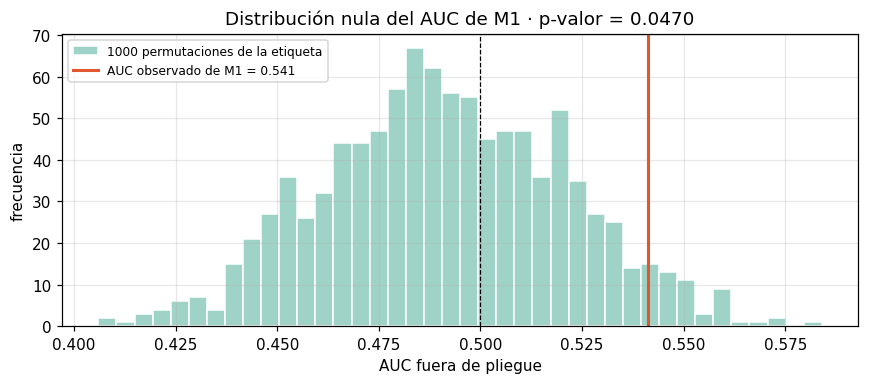

In [15]:
aucs = np.array(c1["aucs_permutados"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(aucs, bins=40, color="#9fd3c7", edgecolor="white", label=f"{len(aucs)} permutaciones de la etiqueta")
ax.axvline(c1["auc_observado"], c="#e4572e", lw=2, label=f"AUC observado de M1 = {c1['auc_observado']:.3f}")
ax.axvline(0.5, c="k", lw=.8, ls="--")
ax.set(xlabel="AUC fuera de pliegue", ylabel="frecuencia",
       title=f"Distribución nula del AUC de M1 · p-valor = {c1['p_valor']:.4f}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 15. Lectura del resultado de M1

In [16]:
auc1, (lo1, hi1), p1 = r1["metricas"]["auc"]["valor"], r1["metricas"]["auc"]["ic95"], c1["p_valor"]
if p1 >= 0.05 and lo1 <= 0.5:
    lectura = "La adquisición no predice la etiqueta mejor que el azar: el atajo por metadatos queda descartado."
elif lo1 <= 0.5:
    lectura = (f"Asociación débil y en el límite: la prueba de permutación la detecta (p = {p1:.3f}), pero el IC 95 % "
               "por bootstrap de pacientes incluye 0,5. La adquisición apenas informa de la etiqueta: no invalida los "
               "modelos de imagen, pero conviene declararlo como amenaza menor y evaluar M3–M7 por estratos de las "
               "variables con efecto consistente en los 5 pliegues (sección 11).")
elif auc1 < 0.6:
    lectura = ("Asociación débil pero distinta del azar entre adquisición y etiqueta. No invalida los modelos de imagen, "
               "pero obliga a evaluarlos estratificando por las variables con efecto consistente (secciones 11–13) "
               "y a declararlo como amenaza a la validez.")
else:
    lectura = ("La adquisición predice la etiqueta de forma apreciable: riesgo serio de atajo. Antes de entrenar M3–M7 "
               "conviene ajustar o estratificar por estos metadatos, o restringir la muestra.")
print(f"M1: AUC {auc1:.3f} [{lo1:.3f}, {hi1:.3f}] · p-valor {p1:.4f}\n→ {lectura}")
print(f"Referencia: M0 (diámetro) AUC {r['metricas']['auc']['valor']:.3f}")

M1: AUC 0.541 [0.496, 0.588] · p-valor 0.0470
→ Asociación débil y en el límite: la prueba de permutación la detecta (p = 0.047), pero el IC 95 % por bootstrap de pacientes incluye 0,5. La adquisición apenas informa de la etiqueta: no invalida los modelos de imagen, pero conviene declararlo como amenaza menor y evaluar M3–M7 por estratos de las variables con efecto consistente en los 5 pliegues (sección 11).
Referencia: M0 (diámetro) AUC 0.936


---
# Parte 3 · M2 — atributos semánticos del radiólogo

**M2** (Tabla 21) predice la etiqueta solo con las **ocho valoraciones semánticas** del radiólogo: seis ordinales
(mediana entre lectores, estandarizadas) y dos nominales (moda entre lectores, codificación one-hot). **La malignidad
nunca es entrada**: es la etiqueta (`tests/test_m2.py` lo comprueba). Imputación, estandarización y categorías se
ajustan solo con el entrenamiento de cada pliegue.

**Cómo leer M2.** Sus cifras **no son una predicción independiente** de la malignidad: las ocho valoraciones las
asignan los mismos radiólogos, en la misma sesión y sobre el mismo nódulo que puntúan como maligno. M2 mide cuánto de
la etiqueta explican esas valoraciones (escenario A) y sirve como **cota y referencia** para M6, no como competidor de
los modelos de imagen (apartado 3.3.5.5 de la memoria).

| Configuración | Estimador | Entradas |
|---|---|---|
| `m2_logistica` | Regresión logística | 8 atributos |
| `m2_bosque` | Bosque aleatorio | 8 atributos |
| `m2_mlp` | Perceptrón multicapa (32-16), la rama tabular que reutilizará M6 | 8 atributos |
| `m2_logistica_diam_vol` | Regresión logística | 8 atributos + diámetro y volumen |
| `m2_bosque_diam_vol` | Bosque aleatorio | 8 atributos + diámetro y volumen |

Las variantes con diámetro y volumen siguen a Hancock y Magnan (2016) y se informan aparte para no mezclar su efecto
con el de los ocho atributos.

## 16. Ejecución de los cinco modelos M2

In [17]:
CFGS_M2 = {"logística": "m2_logistica", "bosque": "m2_bosque", "perceptrón": "m2_mlp",
           "logística + diám./vol.": "m2_logistica_diam_vol", "bosque + diám./vol.": "m2_bosque_diam_vol"}
N_CONTROL_M2 = 0          # p. ej. 200 para añadir el control con etiquetas permutadas (tarda unos minutos)

r2 = {}
for nombre, archivo in CFGS_M2.items():
    r2[nombre] = ejecutar(str(REPO / f"configs/modelos/{archivo}.yaml"), n_control=N_CONTROL_M2)
    a = r2[nombre]["metricas"]["auc"]
    print(f"M2 · {nombre:<24} AUC {a['valor']:.3f} [{a['ic95'][0]:.3f}; {a['ic95'][1]:.3f}] · "
          f"{r2[nombre]['datos']['nodulos']} nódulos · {r2[nombre]['carpeta_resultados'].split('/')[-1]}")

M2 · logística                AUC 0.949 [0.933; 0.963] · 869 nódulos · m2_logistica__R1__s42__b54ad8c-modificado


M2 · bosque                   AUC 0.954 [0.940; 0.966] · 869 nódulos · m2_bosque__R1__s42__b54ad8c-modificado


M2 · perceptrón               AUC 0.946 [0.931; 0.960] · 869 nódulos · m2_mlp__R1__s42__b54ad8c-modificado


M2 · logística + diám./vol.   AUC 0.973 [0.962; 0.982] · 869 nódulos · m2_logistica_diam_vol__R1__s42__b54ad8c-modificado


M2 · bosque + diám./vol.      AUC 0.969 [0.957; 0.979] · 869 nódulos · m2_bosque_diam_vol__R1__s42__b54ad8c-modificado


## 17. M2 frente a M0 y M1
Métricas fuera de pliegue por nódulo con IC 95 % por bootstrap de pacientes; misma partición para todos los modelos.

In [18]:
modelos = {"M0 · diámetro": r, "M1 · metadatos": r1, **{f"M2 · {k}": v for k, v in r2.items()}}
fmt = lambda x: f"{x['valor']:.3f} [{x['ic95'][0]:.3f}; {x['ic95'][1]:.3f}]"
display(pd.DataFrame({mod: {nombres[m]: fmt(x) for m, x in v["metricas"].items()} for mod, v in modelos.items()}).T)

print("AUC de prueba por pliegue:")
display(pd.DataFrame({mod: v["auc_prueba_por_pliegue"] for mod, v in modelos.items()}, index=[f"pliegue {k}" for k in range(5)]).T.round(3))

,AUC,AUPRC,Brier (menor es mejor),Exactitud,Sensibilidad,Especificidad
M0 · diámetro,0.936 [0.917; 0.952],0.926 [0.899; 0.950],0.101 [0.087; 0.117],0.853 [0.826; 0.877],0.822 [0.776; 0.862],0.882 [0.850; 0.911]
M1 · metadatos,0.541 [0.496; 0.588],0.514 [0.463; 0.578],0.252 [0.244; 0.258],0.533 [0.491; 0.576],0.601 [0.541; 0.662],0.469 [0.402; 0.539]
M2 · logística,0.949 [0.933; 0.963],0.935 [0.907; 0.958],0.087 [0.075; 0.101],0.880 [0.858; 0.902],0.895 [0.864; 0.926],0.866 [0.831; 0.897]
M2 · bosque,0.954 [0.940; 0.966],0.949 [0.929; 0.966],0.086 [0.075; 0.097],0.896 [0.874; 0.917],0.912 [0.881; 0.942],0.882 [0.848; 0.910]
M2 · perceptrón,0.946 [0.931; 0.960],0.941 [0.920; 0.959],0.091 [0.076; 0.107],0.865 [0.841; 0.888],0.815 [0.775; 0.854],0.913 [0.884; 0.937]
M2 · logística + diám./vol.,0.973 [0.962; 0.982],0.964 [0.944; 0.979],0.063 [0.053; 0.074],0.912 [0.893; 0.931],0.917 [0.888; 0.944],0.908 [0.880; 0.934]
M2 · bosque + diám./vol.,0.969 [0.957; 0.979],0.963 [0.943; 0.978],0.065 [0.054; 0.077],0.915 [0.894; 0.933],0.922 [0.895; 0.947],0.908 [0.878; 0.935]


AUC de prueba por pliegue:


,pliegue 0,pliegue 1,pliegue 2,pliegue 3,pliegue 4
M0 · diámetro,0.948,0.946,0.934,0.905,0.952
M1 · metadatos,0.565,0.488,0.605,0.540,0.544
M2 · logística,0.962,0.939,0.929,0.965,0.956
M2 · bosque,0.950,0.958,0.961,0.946,0.961
M2 · perceptrón,0.947,0.955,0.935,0.953,0.944
M2 · logística + diám./vol.,0.982,0.971,0.967,0.962,0.984
M2 · bosque + diám./vol.,0.976,0.975,0.972,0.946,0.981


## 18. Diferencia pareada de AUC frente a M0

Mismos nódulos y mismo remuestreo de pacientes para los dos modelos de cada par (2.000 réplicas). Si el IC 95 % no
incluye el 0, la diferencia con el diámetro es estable. Recuerda que M2 parte de las valoraciones del propio radiólogo.

In [19]:
def oof(res):
    return pd.read_csv(Path(res["carpeta_resultados"]) / "predicciones_oof.csv")[["nodule_id", "patient_id", "etiqueta", "probabilidad"]]

base = oof(r).rename(columns={"probabilidad": "M0"})
for k, v in r2.items():
    base = base.merge(oof(v)[["nodule_id", "probabilidad"]].rename(columns={"probabilidad": k}), on="nodule_id")
y_, g_ = base.etiqueta.values, base.patient_id.values
pac = np.unique(g_); idx = {p_: np.flatnonzero(g_ == p_) for p_ in pac}
rng = np.random.default_rng(42); muestras = []
for _ in range(2000):
    s_ = np.concatenate([idx[p_] for p_ in rng.choice(pac, len(pac))])
    if len(np.unique(y_[s_])) == 2:
        muestras.append(s_)
filas = []
for k in r2:
    dif = [roc_auc_score(y_[s_], base[k].values[s_]) - roc_auc_score(y_[s_], base.M0.values[s_]) for s_ in muestras]
    d_ = roc_auc_score(y_, base[k]) - roc_auc_score(y_, base.M0)
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas.append({"modelo": f"M2 · {k}", "AUC": round(roc_auc_score(y_, base[k]), 3), "ΔAUC vs M0": round(d_, 3),
                  "IC 95 %": f"[{lo:+.3f}; {hi:+.3f}]", "excluye 0": not (lo <= 0 <= hi)})
print(f"{len(base)} nódulos comunes · AUC M0 = {roc_auc_score(y_, base.M0):.3f}")
display(pd.DataFrame(filas).set_index("modelo"))

869 nódulos comunes · AUC M0 = 0.936


,AUC,ΔAUC vs M0,IC 95 %,excluye 0
modelo,,,,
M2 · logística,0.949,0.013,[-0.008; +0.034],False
M2 · bosque,0.954,0.018,[+0.001; +0.037],True
M2 · perceptrón,0.946,0.011,[-0.010; +0.031],False
M2 · logística + diám./vol.,0.973,0.037,[+0.025; +0.052],True
M2 · bosque + diám./vol.,0.969,0.033,[+0.022; +0.047],True


## 19. Curvas ROC

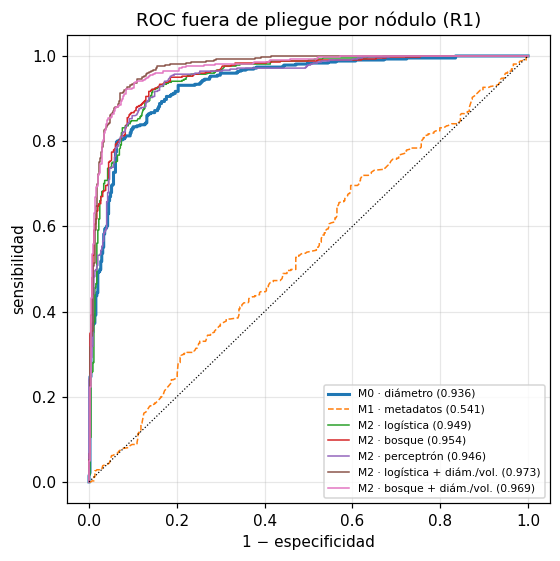

In [20]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
curvas = {"M0 · diámetro": oof(r), "M1 · metadatos": oof(r1), **{f"M2 · {k}": oof(v) for k, v in r2.items()}}
for k, p_ in curvas.items():
    fpr, tpr, _ = roc_curve(p_.etiqueta, p_.probabilidad)
    ax.plot(fpr, tpr, lw=2 if k.startswith("M0") else 1, ls="--" if k.startswith("M1") else "-",
            label=f"{k} ({roc_auc_score(p_.etiqueta, p_.probabilidad):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=.8)
ax.set(xlabel="1 − especificidad", ylabel="sensibilidad", title="ROC fuera de pliegue por nódulo (R1)")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

## 20. Qué atributos pesan (regresión logística)

Coeficientes de `m2_logistica` en cada pliegue, con la misma lectura que en M1: las variables ordinales están
estandarizadas (log-odds por desviación típica); las nominales son indicadores one-hot (categoría frente a la media);
`missingindicator_*` marca las modas empatadas que se imputaron. Un efecto es más creíble si **mantiene el signo en los
5 pliegues**. Hancock y Magnan (2016) ordenaron los atributos así: espiculación, lobulación, subtlety y calcificación.

,media,DT,OR (e^media),pliegues con el mismo signo
calcification_moda_6.0,2.387,0.148,10.883,5
calcification_moda_3.0,-2.249,0.059,0.106,5
subtlety_mediana,1.942,0.104,6.974,5
missingindicator_calcification_moda_1.0,-1.488,0.226,0.226,5
missingindicator_calcification_moda_0.0,1.487,0.223,4.422,5
lobulation_mediana,0.617,0.160,1.853,5
spiculation_mediana,0.608,0.199,1.838,5
texture_mediana,-0.545,0.129,0.580,5
margin_mediana,-0.468,0.211,0.626,5
sphericity_mediana,0.351,0.042,1.420,5


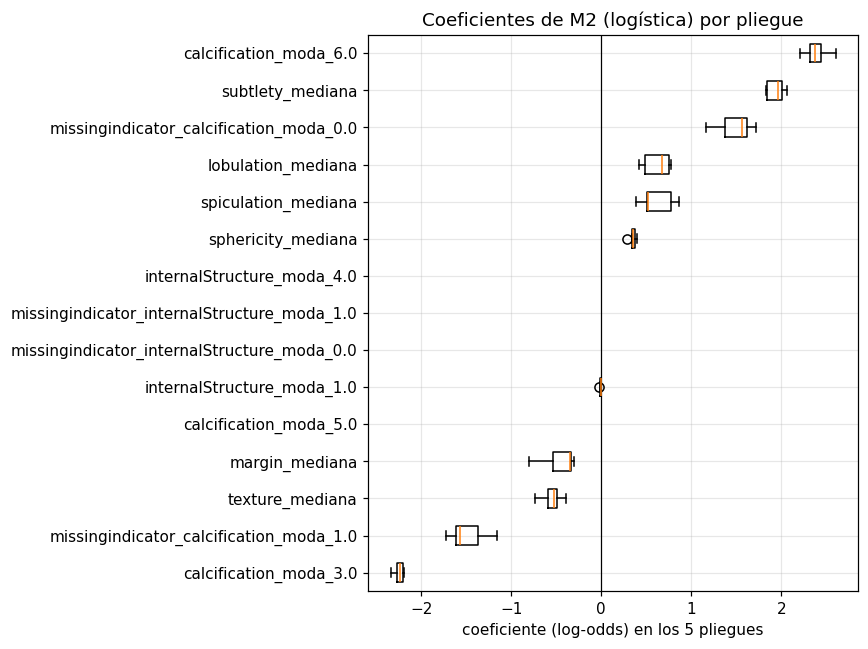

In [21]:
coef2 = pd.DataFrame(r2["logística"]["coeficientes_por_pliegue"]).drop(columns="intercepto")
res2 = pd.DataFrame({"media": coef2.mean(), "DT": coef2.std(ddof=1), "OR (e^media)": np.exp(coef2.mean()),
                     "pliegues con el mismo signo": coef2.apply(lambda c_: max((c_ > 0).sum(), (c_ < 0).sum()))})
display(res2.sort_values("media", key=abs, ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 0.32 * len(coef2.columns) + 1.2))
orden = coef2.mean().sort_values().index
ax.boxplot([coef2[c_] for c_ in orden], orientation="horizontal", tick_labels=list(orden))
ax.axvline(0, c="k", lw=.8); ax.set(xlabel="coeficiente (log-odds) en los 5 pliegues", title="Coeficientes de M2 (logística) por pliegue")
plt.tight_layout(); plt.show()

## 21. Lectura del resultado de M2

In [22]:
dif = pd.DataFrame(filas).set_index("modelo")                    # sección 18
a0 = r["metricas"]["auc"]["valor"]
ocho = dif[~dif.index.str.contains("diám")]
con_tam = dif[dif.index.str.contains("diám")]
print(f"M0 (diámetro) = {a0:.3f}")
print(f"M2 con los 8 atributos: AUC {ocho.AUC.min():.3f}–{ocho.AUC.max():.3f}; "
      f"superan a M0 con IC que excluye el 0: {', '.join(ocho.index[ocho['excluye 0']]) or 'ninguno'}")
print(f"M2 con diámetro y volumen: AUC {con_tam.AUC.min():.3f}–{con_tam.AUC.max():.3f}; "
      f"superan a M0 con IC que excluye el 0: {', '.join(con_tam.index[con_tam['excluye 0']]) or 'ninguno'}")
print("""
Lectura: con solo las ocho valoraciones, M2 queda a la altura del diámetro (ΔAUC de +0,01 a +0,02, con intervalos que
rozan o incluyen el 0); al añadir el diámetro y el volumen de los contornos, la mejora es clara y estable, como en
Hancock y Magnan (2016). Como las valoraciones las asigna el mismo lector que puntúa la malignidad, M2 es una cota de
lo que explican, no una predicción independiente: fija la referencia del escenario A para M6 y no compite con los
modelos de imagen, que se contrastan frente a M0 (H1).""")

M0 (diámetro) = 0.936
M2 con los 8 atributos: AUC 0.946–0.954; superan a M0 con IC que excluye el 0: M2 · bosque
M2 con diámetro y volumen: AUC 0.969–0.973; superan a M0 con IC que excluye el 0: M2 · logística + diám./vol., M2 · bosque + diám./vol.

Lectura: con solo las ocho valoraciones, M2 queda a la altura del diámetro (ΔAUC de +0,01 a +0,02, con intervalos que
rozan o incluyen el 0); al añadir el diámetro y el volumen de los contornos, la mejora es clara y estable, como en
Hancock y Magnan (2016). Como las valoraciones las asigna el mismo lector que puntúa la malignidad, M2 es una cota de
lo que explican, no una predicción independiente: fija la referencia del escenario A para M6 y no compite con los
modelos de imagen, que se contrastan frente a M0 (H1).
